IMPORTS

In [11]:
import glob
import os
import shutil
import random

import h5py
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader

from dataset import Dataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PATHS

In [12]:
DATASET_PATH = "/home/dinis/Desktop/Universidade/Cadeiras/Ano4-Q1/AE4353 Artificial Intelligence for Aerospace Control and Operations/Competition/Data/ae4353-2026"

OUTPUT_PATH = "/home/dinis/Desktop/Universidade/Cadeiras/Ano4-Q1/AE4353 Artificial Intelligence for Aerospace Control and Operations/Competition/Output/model1"

In [13]:
if not os.path.isdir(DATASET_PATH):
    raise FileNotFoundError(
        f"There is no folder at {DATASET_PATH}.\n"
        "Copy the real path from the Input panel on the right: expand the "
        "competition data, hover over its folder, and click the copy-path icon."
    )

shutil.copy(f"{DATASET_PATH}/metric.py", "metric.py")
from metric import rle_encode, rle_decode, global_dice, write_submission

train_files = sorted(glob.glob(f"{DATASET_PATH}/train_*.h5"))
test_files = sorted(glob.glob(f"{DATASET_PATH}/test_*.h5"))
print("Paths initialized.")

Paths initialized.


SEED

In [14]:
SEED = 2006                                   # any fixed number
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)                     # seeds the GPU as well
torch.backends.cudnn.benchmark = False      # the same algorithms on every run
torch.backends.cudnn.deterministic = True

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


LOADER

In [15]:
OVERFIT = False

BATCH_SIZE = 8
NUM_WORKERS = 4
NUM_IMAGES = 50
VAL_SPLIT = 0.2

train_dataset = Dataset(train_files, is_train=True)

if OVERFIT:
    train_dataset = torch.utils.data.Subset(train_dataset, range(50))
    train_dataset = train_dataset
    val_dataset = train_dataset 
else:
    val_size = int(len(train_dataset) * VAL_SPLIT)
    train_size = len(train_dataset) - val_size
    train_dataset, val_dataset = torch.utils.data.random_split(
        train_dataset, 
        [train_size, val_size],
        generator=torch.Generator().manual_seed(SEED)
    )

test_dataset = Dataset(test_files, is_train=False)


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    worker_init_fn=seed_worker,
    generator=torch.Generator().manual_seed(SEED),
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    worker_init_fn=seed_worker,
    generator=torch.Generator().manual_seed(SEED),
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    worker_init_fn=seed_worker,
    generator=torch.Generator().manual_seed(SEED),
    shuffle=True
)



Plot Dataset

Found 2119 images containing contrails.


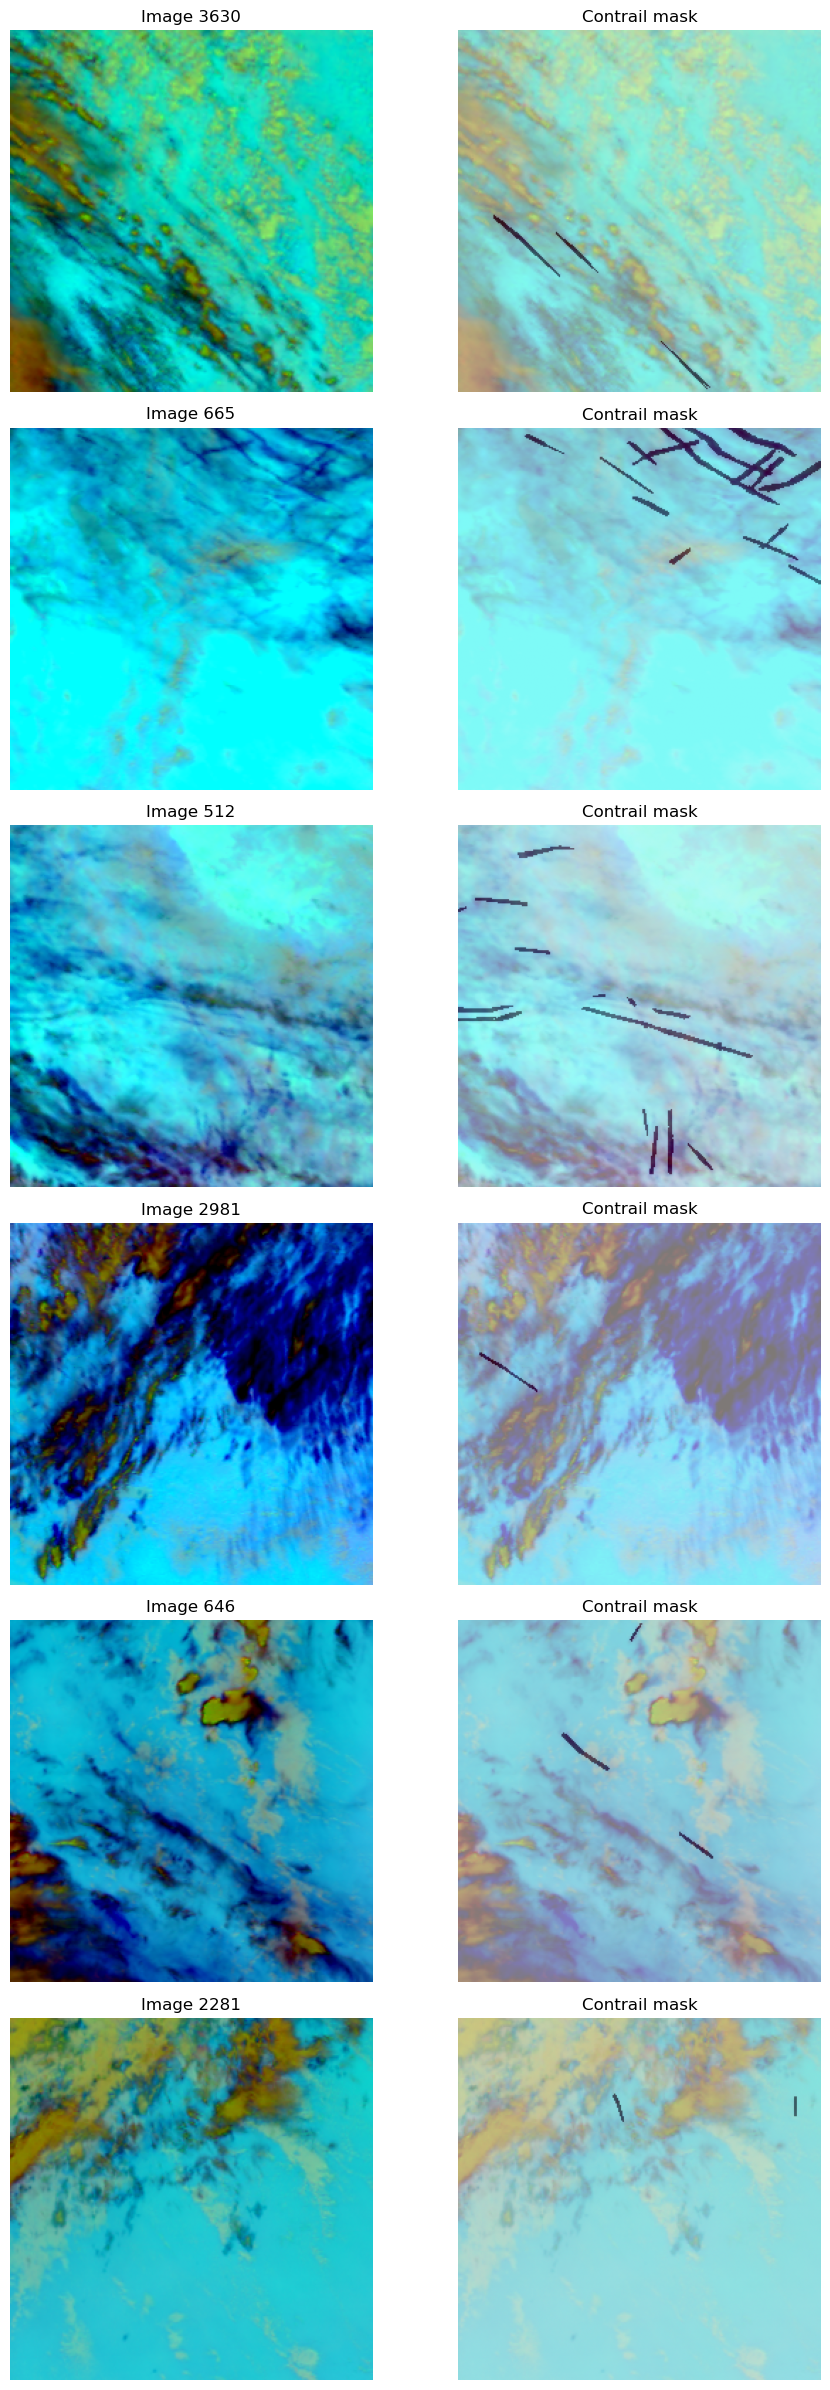

In [16]:
PLOT_INPUT = True

if PLOT_INPUT:

    positive_indices = []
    for index in range(len(train_dataset)):
        _, mask = train_dataset[index]
        if torch.any(mask > 0):
            positive_indices.append(index)

    print(f"Found {len(positive_indices)} images containing contrails.")

    n_to_plot = min(6, len(positive_indices))

    if n_to_plot:
        selected_indices = random.sample(positive_indices, n_to_plot)

        fig, axes = plt.subplots(n_to_plot, 2, figsize=(10, 4 * n_to_plot))
        axes = np.atleast_2d(axes)

        for row, index in enumerate(selected_indices):
            image, mask = train_dataset[index]
            image_np = image.permute(1, 2, 0).numpy()
            mask_np = mask.squeeze(0).numpy()

            axes[row, 0].imshow(image_np)
            axes[row, 0].set_title(f"Image {index}")
            axes[row, 0].axis("off")

            axes[row, 1].imshow(image_np)
            axes[row, 1].imshow(mask_np, cmap="Reds", alpha=0.5)
            axes[row, 1].set_title("Contrail mask")
            axes[row, 1].axis("off")

        plt.tight_layout()
        plt.show()

Model

In [17]:
POOL_KERNEL_SIZE = 2
POOL_STRIDE = 2
CONV_KERNEL_SIZE = 3

class Contrail_CNN(nn.Module):
    
    def __init__(self, input_channels=3, output_channels=1):
        super().__init__()

        # Encoder Layer 1 (256x256x3->128x128x12)
        self.enc1 = nn.Sequential(
            nn.Conv2d(input_channels, 64, kernel_size=CONV_KERNEL_SIZE, padding='same'),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),   
        )
        self.pool1 = nn.MaxPool2d(kernel_size=POOL_KERNEL_SIZE, stride=POOL_STRIDE)

        # Encoder Layer 2 (128x128x12->64x64x24)
        self.enc2 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=CONV_KERNEL_SIZE, padding='same'),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
        )
        self.pool2 = nn.MaxPool2d(kernel_size=POOL_KERNEL_SIZE, stride=POOL_STRIDE)

        # Encoder Layer 3 (64x64x24->32x32x48)
        self.enc3 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=CONV_KERNEL_SIZE, padding='same'),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
        )
        self.pool3 = nn.MaxPool2d(kernel_size=POOL_KERNEL_SIZE, stride=POOL_STRIDE)

        # Encoder Layer 4 (32x32x48->16x16x96)
        self.enc4 = nn.Sequential(
            nn.Conv2d(256, 512, kernel_size=CONV_KERNEL_SIZE, padding='same'),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),
        )
        self.pool4 = nn.MaxPool2d(kernel_size=POOL_KERNEL_SIZE, stride=POOL_STRIDE)

        # Bottleneck Layer (16x16x96->16x16x96)
        self.bottleneck = nn.Sequential(
            nn.Conv2d(512, 512, kernel_size=CONV_KERNEL_SIZE, padding='same'),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),
        )

        # Decoder Layer 4 (16x16x96->32x32x48)
        self.up4 = nn.ConvTranspose2d(512, 256, kernel_size=POOL_KERNEL_SIZE, stride=POOL_STRIDE)
        self.dec4 = nn.Sequential(
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
        )

        # Decoder Layer 3 (32x32x48->64x64x24)
        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=POOL_KERNEL_SIZE, stride=POOL_STRIDE)
        self.dec3 = nn.Sequential(
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
        )

        # Decoder Layer 2 (64x64x24->128x128x12)
        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=POOL_KERNEL_SIZE, stride=POOL_STRIDE)
        self.dec2 = nn.Sequential(
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
        )

        # Decoder Layer 1 (128x128x12->256x256x1)
        self.up1 = nn.ConvTranspose2d(64, output_channels, kernel_size=POOL_KERNEL_SIZE, stride=POOL_STRIDE)
        self.dec1 = nn.Sequential(
            nn.BatchNorm2d(output_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        e4 = self.enc4(self.pool3(e3))

        b = self.bottleneck(self.pool4(e4))

        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.out_conv(d1)

model = Contrail_CNN(input_channels=3, output_channels=1)


POOL_KERNEL_SIZE = 2
POOL_STRIDE = 2
CONV_KERNEL_SIZE = 3


class Contrail_CNN(nn.Module):
    def __init__(self, input_channels=3, output_channels=1):
        super().__init__()

        # --- Encoder ---

        # Level 1: 256x256x3 -> 128x128x64
        self.enc1 = nn.Sequential(
            nn.Conv2d(input_channels, 64, kernel_size=CONV_KERNEL_SIZE, padding="same"),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
        )
        self.pool1 = nn.MaxPool2d(kernel_size=POOL_KERNEL_SIZE, stride=POOL_STRIDE)

        # Level 2: 128x128x64 -> 64x64x128
        self.enc2 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=CONV_KERNEL_SIZE, padding="same"),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
        )
        self.pool2 = nn.MaxPool2d(kernel_size=POOL_KERNEL_SIZE, stride=POOL_STRIDE)

        # Level 3: 64x64x128 -> 32x32x256
        self.enc3 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=CONV_KERNEL_SIZE, padding="same"),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
        )
        self.pool3 = nn.MaxPool2d(kernel_size=POOL_KERNEL_SIZE, stride=POOL_STRIDE)

        # Level 4: 32x32x256 -> 16x16x512
        self.enc4 = nn.Sequential(
            nn.Conv2d(256, 512, kernel_size=CONV_KERNEL_SIZE, padding="same"),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),
        )
        self.pool4 = nn.MaxPool2d(kernel_size=POOL_KERNEL_SIZE, stride=POOL_STRIDE)

        # --- Bottleneck ---

        # Level 5: 16x16x512 -> 16x16x512
        self.bottleneck = nn.Sequential(
            nn.Conv2d(512, 512, kernel_size=CONV_KERNEL_SIZE, padding="same"),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),
        )

        # --- Decoder ---
        # Level 4: 16x16x512 -> 32x32x256
        self.up4 = nn.ConvTranspose2d(512, 256, kernel_size=POOL_KERNEL_SIZE, stride=POOL_STRIDE)
        self.dec4 = nn.Sequential(
            nn.Conv2d(256 + 512, 256, kernel_size=CONV_KERNEL_SIZE, padding="same"), # 256 + 512 to account for concatenation with encoder output
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
        )

        # Level 3: 32x32x256 -> 64x64x128
        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=POOL_KERNEL_SIZE, stride=POOL_STRIDE)
        self.dec3 = nn.Sequential(
            nn.Conv2d(128 + 256, 128, kernel_size=CONV_KERNEL_SIZE, padding="same"),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
        )

        # Level 2: 64x64x128 -> 128x128x64
        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=POOL_KERNEL_SIZE, stride=POOL_STRIDE)
        self.dec2 = nn.Sequential(
            nn.Conv2d(64 + 128, 64, kernel_size=CONV_KERNEL_SIZE, padding="same"),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
        )
        # Level 1: 128x128x64 -> 256x256x64
        self.up1 = nn.ConvTranspose2d(64, 64, kernel_size=POOL_KERNEL_SIZE, stride=POOL_STRIDE)
        self.dec1 = nn.Sequential(
            nn.Conv2d(64 + 64, 64, kernel_size=CONV_KERNEL_SIZE, padding="same"),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
        )

        # Output layer: 256x256x64 -> 256x256x1
        self.out_conv = nn.Conv2d(64, output_channels, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        e4 = self.enc4(self.pool3(e3))

        b = self.bottleneck(self.pool4(e4))

        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.out_conv(d1)

model = Contrail_CNN(input_channels=3, output_channels=1)
model = model.to(device)

Loss & Optimizer

In [18]:
LEARNING_RATE = 0.001

# TODO: Change
class DiceLoss(nn.Module):
    def __init__(self, eps: float = 1e-6):
        super().__init__()
        self.eps = eps

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        # Convert logits to probabilities
        probs = torch.sigmoid(logits)

        # Flatten batch items across all spatial dimensions: (B, -1)
        probs = probs.view(probs.size(0), -1)
        targets = targets.view(targets.size(0), -1).float()

        # Compute Dice per sample in the batch
        intersection = (probs * targets).sum(dim=1)
        cardinality = probs.sum(dim=1) + targets.sum(dim=1)

        dice = (2.0 * intersection + self.eps) / (cardinality + self.eps)
        
        # Return batch mean loss
        return (1.0 - dice).mean()

import torch.nn.functional as F

class BCEDiceLoss(nn.Module):
    def __init__(self, bce_weight=0.5, dice_weight=0.5, eps=1e-6):
        super().__init__()
        self.bce_weight = bce_weight
        self.dice_weight = dice_weight
        self.eps = eps
        # Use BCEWithLogitsLoss for numerical stability (combines Sigmoid + BCE)
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        # 1. Compute BCE Loss directly from logits
        bce_loss = self.bce(logits, targets)

        # 2. Compute Soft Dice Loss
        probs = torch.sigmoid(logits)
        
        # Flatten predictions and targets to (Batch, N_pixels)
        probs = probs.view(probs.size(0), -1)
        targets = targets.view(targets.size(0), -1).float()

        intersection = (probs * targets).sum(dim=1)
        cardinality = probs.sum(dim=1) + targets.sum(dim=1)

        dice_score = (2.0 * intersection + self.eps) / (cardinality + self.eps)
        dice_loss = (1.0 - dice_score).mean()

        # 3. Combine both losses
        return (self.bce_weight * bce_loss) + (self.dice_weight * dice_loss)

# Update criterion and lower the learning rate for Adam
criterion = BCEDiceLoss()


# criterion = DiceLoss()

optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)



Training

In [20]:
EPOCHS = 10000
THRESHOLD = 0.5

loss_history = []
best_global_dice = 0.0

os.makedirs(OUTPUT_PATH, exist_ok=True)

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0

    for images, masks in train_loader:
        images = images.to(device)
        masks = masks.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    avg_loss = running_loss / len(train_loader)
    loss_history.append(avg_loss)

    # Validation
    model.eval()
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for images, masks in val_loader:
            images = images.to(device)
            masks = masks.to(device)
            outputs = model(images)
            preds = (torch.sigmoid(outputs) > THRESHOLD)
            all_preds.append(preds.cpu().numpy())
            all_targets.append(masks.cpu().numpy())

    all_preds = np.concatenate(all_preds, axis=0)
    all_targets = np.concatenate(all_targets, axis=0)
    val_dice = global_dice(all_preds, all_targets)

    print(f"Epoch [{epoch + 1}/{EPOCHS}], Loss: {avg_loss:.4f}, Validation Dice: {val_dice:.4f}")

    if val_dice > best_global_dice:
        best_global_dice = val_dice
        torch.save(model.state_dict(), os.path.join(OUTPUT_PATH, "best_model.pth"))
        print(f"New best model saved with Validation Dice: {best_global_dice:.4f}")
    

Epoch [1/10000], Loss: 0.4553, Validation Dice: 0.3883
New best model saved with Validation Dice: 0.3883
Epoch [2/10000], Loss: 0.4425, Validation Dice: 0.3843
Epoch [3/10000], Loss: 0.4349, Validation Dice: 0.4358
New best model saved with Validation Dice: 0.4358
Epoch [4/10000], Loss: 0.4297, Validation Dice: 0.4474
New best model saved with Validation Dice: 0.4474
Epoch [5/10000], Loss: 0.4264, Validation Dice: 0.4496
New best model saved with Validation Dice: 0.4496
Epoch [6/10000], Loss: 0.4219, Validation Dice: 0.4748
New best model saved with Validation Dice: 0.4748
Epoch [7/10000], Loss: 0.4197, Validation Dice: 0.4633
Epoch [8/10000], Loss: 0.4165, Validation Dice: 0.5031
New best model saved with Validation Dice: 0.5031
Epoch [9/10000], Loss: 0.4134, Validation Dice: 0.5166
New best model saved with Validation Dice: 0.5166
Epoch [10/10000], Loss: 0.4121, Validation Dice: 0.5128
Epoch [11/10000], Loss: 0.4100, Validation Dice: 0.5244
New best model saved with Validation Dice: 

KeyboardInterrupt: 

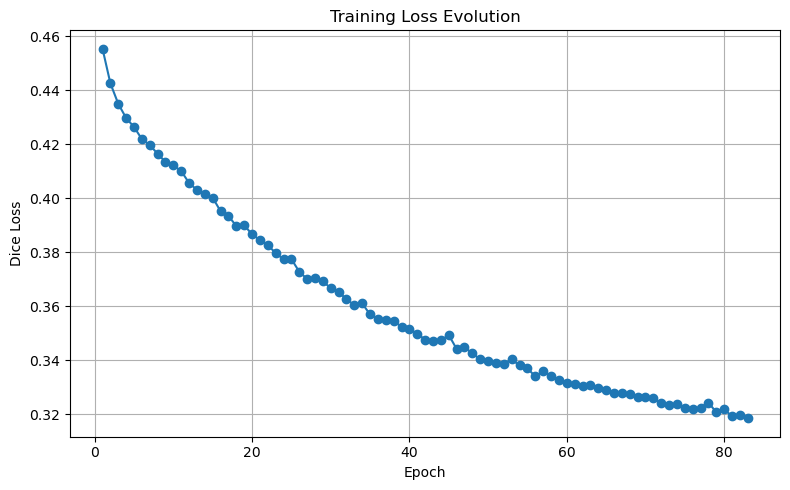

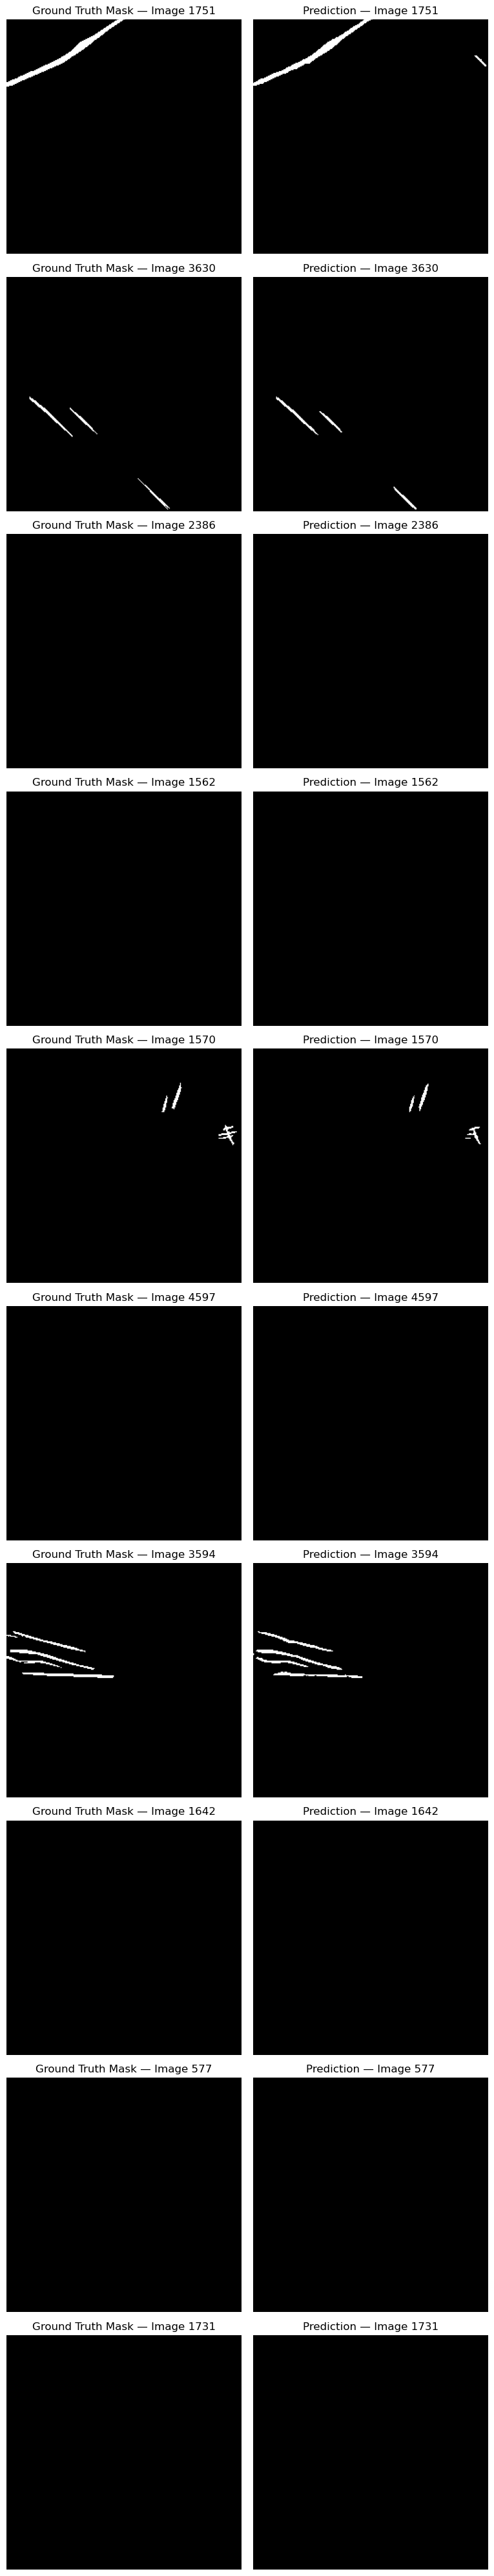

In [21]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(range(1, len(loss_history) + 1), loss_history, marker="o")
ax.set_xlabel("Epoch")
ax.set_ylabel("Dice Loss")
ax.set_title("Training Loss Evolution")
ax.grid(True)

plt.tight_layout()
plt.show()


model.eval()

selected_indices = random.sample(
    range(len(train_dataset)),
    min(10, len(train_dataset))
)

fig, axes = plt.subplots(
    len(selected_indices),
    2,
    figsize=(8, 4 * len(selected_indices))
)

axes = np.atleast_2d(axes)

with torch.no_grad():
    for row, sample_index in enumerate(selected_indices):
        image, target_mask = train_dataset[sample_index]

        prediction = model(image.unsqueeze(0).to(device))
        prediction = torch.sigmoid(prediction).squeeze().cpu().numpy()

        image_np = image.permute(1, 2, 0).numpy()
        target_np = target_mask.squeeze().numpy()

        axes[row, 0].imshow(target_np, cmap="gray")
        axes[row, 0].set_title(f"Ground Truth Mask — Image {sample_index}")
        axes[row, 0].axis("off")

        axes[row, 1].imshow(prediction > 0.5, cmap="gray")
        axes[row, 1].set_title(f"Prediction — Image {sample_index}")
        axes[row, 1].axis("off")

plt.tight_layout()
plt.show()


In [22]:

torch.save(model.state_dict(), os.path.join(OUTPUT_PATH, "last_model.pth"))
